# Optimisation de la gestion d'un élevage de pintades

**Projet : Recherche opérationnelle**

**Réalisé par :**
- Mohamed Khalid KACIMI
- Charafeddin El AKKAD

## 1. Présentation du projet

Ce projet consiste à construire un modèle mathématique et informatique pour optimiser la gestion d'un élevage de pintades sur un horizon de **60 mois**, découpé en **15 périodes de 4 mois**.

À chaque période, l'éleveur décide combien d'adultes, d'œufs, de poussins et de jeunes vendre ou conserver. Ces décisions doivent respecter les contraintes biologiques, financières et matérielles de l'exploitation.

## 2. Objectif

Déterminer une stratégie de gestion qui maximise la richesse économique à la fin de l'horizon, en tenant compte de la trésorerie et de la valeur du cheptel restant.

## 3. Méthode d'optimisation

Les quantités d'animaux et d'œufs sont nécessairement entières. Le modèle est donc un **programme linéaire en nombres entiers mixtes** : les variables de quantité sont entières, tandis que la trésorerie reste continue.

Le modèle est construit avec **PuLP 3.3.x** et résolu avec un solveur compatible, par exemple CBC.





### Bibliothèques et exécution
Le notebook nécessite `pulp` (version 3.3.x conseillée), `pandas`, `matplotlib` et `nbformat` pour la comparaison facultative. Si PuLP est absent, exécuter `%pip install pulp==3.3.0` dans une cellule puis redémarrer le noyau. **Ne pas installer systématiquement à chaque exécution.**

**Mode d'emploi :** exécuter toutes les cellules depuis le début. Les anciennes sorties sont volontairement effacées ; les tableaux et graphiques sont à recalculer localement avant de remettre le projet.


In [30]:

%pip install pulp==3.3.0



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 1. IMPORTATION DES BIBLIOTHEQUES

import pandas as pd
import pulp
import matplotlib.pyplot as plt

print("Version de PuLP :", pulp.__version__)

Version de PuLP : 3.3.0


## 2. Hypothèses et conventions du modèle

### 2.1 Horizon temporel

- Durée totale : 60 mois, soit 5 ans.
- Durée d'une période : 4 mois.
- Nombre de périodes : \(60/4=15\).

### 2.2 Cycle biologique

Le modèle suit le cycle suivant :

$$
\text{Adultes} \rightarrow \text{Œufs} \rightarrow\text{Poussins} \rightarrow \text{Jeunes} \rightarrow \text{Adultes}
$$

Les œufs incubés donnent des poussins disponibles pendant la même période. Cette hypothèse simplifie le délai d'incubation, qui est court par rapport à une période de quatre mois.

Une période est retenue pour chaque transition :
- Poussin conservé en période $t$ : devient jeune en période $t+1$.
- Jeune conservé en période $t$ : devient adulte en période $t+1$.

### 2.3 Entiers et taux moyens

Les nombres d'œufs et d'animaux sont entiers. En revanche, les taux de fertilité, d'éclosion et de mortalité sont des moyennes : leur application directe peut produire des résultats décimaux.

Pour conserver des effectifs entiers, le modèle arrondit les effectifs attendus au plus proche entier. Mathématiquement, si $X$ est l'effectif entier et $qY$ l'effectif moyen attendu :
$$
qY-0,5+\varepsilon \leq X \leq qY+0,5
$$
On fixe $\varepsilon=10^{-6}$ afin de choisir l’entier supérieur lorsque la valeur attendue termine exactement par 0,5 (arrondi au plus proche avec demi-unités vers le haut). Cette convention est une approximation déterministe des taux moyens ; elle ne simule pas l'aléa réel des naissances et des décès.

### 2.4 Ordre des décisions dans une période

On suppose que les ventes sont décidées au début de la période. Les animaux conservés restent dans l'élevage pendant la période, occupent de la surface et génèrent les coûts d'alimentation et de suivi. Les mortalités interviennent ensuite.

### 2.5 Reproduction sexuée

Le modèle distingue les femelles et les mâles adultes, ainsi que leur descendance. **Seules les femelles reproductrices pondent.** Le nombre de femelles conservées ne peut pas dépasser quatre fois le nombre de mâles reproducteurs conservés, dans le scénario de référence. Les paramètres de sexe (80 femelles, 20 mâles au départ, 12,5 œufs par femelle et ratio 4:1) sont **fictifs**, choisis pour l'étude et non validés sur le terrain.

### 2.6 Fin de l'horizon

Les animaux conservés à la fin de la période 15 reçoivent une valeur résiduelle. Cette valeur est ajoutée à la trésorerie finale pour éviter de considérer le cheptel restant comme sans valeur.


In [32]:
# 2. PARAMETRES TEMPORELS

DUREE_TOTALE_MOIS = 60
DUREE_PERIODE_MOIS = 4

N_PERIODES = DUREE_TOTALE_MOIS // DUREE_PERIODE_MOIS
T = range(1, N_PERIODES + 1)
PERIODES_STOCK = range(0, N_PERIODES + 1)

print("Durée totale :", DUREE_TOTALE_MOIS, "mois")
print("Durée d'une période :", DUREE_PERIODE_MOIS, "mois")
print("Nombre de périodes :", N_PERIODES)


Durée totale : 60 mois
Durée d'une période : 4 mois
Nombre de périodes : 15


## 3. Paramètres du modèle

Les paramètres sont des données connues avant l'optimisation. Ils décrivent :
- la population initiale ;
- les rendements biologiques et les taux de mortalité ;
- les prix de vente ;
- les coûts d'exploitation ;
- la surface disponible ;
- le budget initial ;
- la capacité d'incubation ;
- la valeur résiduelle des animaux en fin d'horizon.

Les taux sont compris entre 0 et 1. Les quantités initiales doivent être des entiers non négatifs.

Les données ci-dessous sont conservées comme **scénario fictif de test**. Elles ne constituent pas des références zootechniques.


In [33]:
# 3. PARAMETRES DU MODELE

# Population initiale : nombres entiers d'animaux
population_initiale = {
    "adultes": 100,
    "poussins": 0,
    "jeunes": 0
}

# Paramètres biologiques
biologie = {
    "oeufs_par_adulte": 10,
    "fertilite": 0.80,
    "eclosion": 0.75,
    "survie_eclosion": 0.90,
    "mortalite_adultes": 0.02,
    "mortalite_poussins": 0.08,
    "mortalite_jeunes": 0.04
}

# Prix de vente (par unité)
prix = {
    "adulte": 25,
    "oeuf": 1.5,
    "poussin": 5,
    "jeune": 12
}

# Coûts par animal conservé et par période de 4 mois
couts = {
    "alimentation_adulte": 6,
    "alimentation_poussin": 2,
    "alimentation_jeune": 4,
    "incubation_oeuf": 0.5,
    "veterinaire_adulte": 1,
    "veterinaire_poussin": 0.5,
    "veterinaire_jeune": 0.8,
    "entretien_fixe": 100
}

# Surface en m²
surface = {
    "surface_max": 1000,
    "adulte": 0.5,
    "poussin": 0.1,
    "jeune": 0.25
}

# Transport : tarif proportionnel au poids (hypothèses de simulation)
# On ne modélise pas des trajets entiers : 20 / 500 est un coût moyen par kg.
transport = {
    "poids_oeuf_kg": 0.10,
    "poids_poussin_kg": 0.40,  # hypothèse supplémentaire propre à notre modèle
    "poids_jeune_kg": 1.30,
    "poids_adulte_kg": 1.80,
    "capacite_reference_kg": 500,
    "cout_reference_euros": 20
}
cout_transport_kg = transport["cout_reference_euros"] / transport["capacite_reference_kg"]

budget_initial = 10000
capacite_incubation = 500

# Valeur résiduelle par animal à la fin du projet
valeur_residuelle = {
    "adulte": 25,
    "poussin": 5,
    "jeune": 12
}

print("Paramètres chargés.")


# AJOUT : paramètres fictifs pour distinguer les sexes
SEXES = ["F", "M"]
adultes_initiaux_sexe = {"F": 80, "M": 20}
oeufs_par_femelle = 12.5
femelles_par_male = 4
# 80 femelles x 12,5 = 1000 œufs : même production de départ
# que les 100 adultes x 10 du modèle initial.
assert sum(adultes_initiaux_sexe.values()) == population_initiale["adultes"]
assert population_initiale["poussins"] == population_initiale["jeunes"] == 0


Paramètres chargés.


## 4. Vérification des paramètres

Cette étape ne crée pas encore de décision. Elle sert à afficher les données d'entrée et à repérer une erreur de saisie avant de construire le modèle.

On vérifie notamment que :
- les effectifs initiaux sont entiers et positifs ;
- les taux biologiques sont compris entre 0 et 1 ;
- la durée donne bien un nombre entier de périodes.


In [34]:
# 4. VERIFICATION DES PARAMETRES

assert N_PERIODES == 15
assert all(isinstance(v, int) and v >= 0
           for v in population_initiale.values())

for nom, taux in biologie.items():
    if nom.startswith("mortalite_") or nom in ("fertilite", "eclosion", "survie_eclosion"):
        assert 0 <= taux <= 1, f"Taux invalide : {nom}"

print("Population initiale :")
display(pd.Series(population_initiale, name="Effectif"))

print("Paramètres biologiques :")
display(pd.Series(biologie, name="Valeur"))

print("Prix :")
display(pd.Series(prix, name="Prix unitaire"))

print("Coûts :")
display(pd.Series(couts, name="Coût"))

print("Surface :")
display(pd.Series(surface, name="Valeur"))

print("Budget initial :", budget_initial)
print("Coût de transport supposé (€/kg) :", round(cout_transport_kg, 4))
assert transport["capacite_reference_kg"] > 0
assert all(v >= 0 for v in transport.values())


Population initiale :


adultes     100
poussins      0
jeunes        0
Name: Effectif, dtype: int64

Paramètres biologiques :


oeufs_par_adulte      10.00
fertilite              0.80
eclosion               0.75
survie_eclosion        0.90
mortalite_adultes      0.02
mortalite_poussins     0.08
mortalite_jeunes       0.04
Name: Valeur, dtype: float64

Prix :


adulte     25.0
oeuf        1.5
poussin     5.0
jeune      12.0
Name: Prix unitaire, dtype: float64

Coûts :


alimentation_adulte       6.0
alimentation_poussin      2.0
alimentation_jeune        4.0
incubation_oeuf           0.5
veterinaire_adulte        1.0
veterinaire_poussin       0.5
veterinaire_jeune         0.8
entretien_fixe          100.0
Name: Coût, dtype: float64

Surface :


surface_max    1000.00
adulte            0.50
poussin           0.10
jeune             0.25
Name: Valeur, dtype: float64

Budget initial : 10000
Coût de transport supposé (€/kg) : 0.04


## 5. Création du problème d'optimisation

On cherche à **maximiser** la richesse finale. La fonction objectif sera ajoutée après la définition des variables et des contraintes.

Un problème d'optimisation est représenté par :
- une fonction objectif ;
- des variables de décision ;
- des contraintes.

Les variables sont créées avec `pulp.LpVariable.dicts` puis reliées au problème par les contraintes.


In [35]:
# 5. INITIALISATION DU MODELE

modele = pulp.LpProblem(
    name="Optimisation_Elevage_Pintades",
    sense=pulp.LpMaximize
)

print("Modèle d'optimisation créé.")


Modèle d'optimisation créé.


## 6. Variables de décision

Les variables de décision représentent les choix de l'éleveur à chaque période :

- $V^A_t$ : adultes vendus ;
- $R^A_t$ : adultes conservés pour la reproduction ;
- $E_t$ : œufs produits ;
- $V^E_t$ : œufs vendus ;
- $I_t$ : œufs incubés ;
- $V^P_t,C^P_t$ : poussins vendus et conservés ;
- $V^J_t,C^J_t$ : jeunes vendus et conservés.

**Toutes ces variables sont entières et non négatives**, car elles représentent des nombres d'unités physiques.

Dans PuLP 3.3, le paramètre `cat="Integer"` impose l'intégralité de chaque variable créée par `LpVariable.dicts`.


In [36]:
# 6. VARIABLES DE DECISION : QUANTITES ENTIERES

V_adultes = pulp.LpVariable.dicts(
    "Adultes_vendus", T, lowBound=0, cat="Integer"
)

R_adultes = pulp.LpVariable.dicts(
    "Adultes_reproducteurs", T, lowBound=0, cat="Integer"
)

E_produits = pulp.LpVariable.dicts(
    "Oeufs_produits", T, lowBound=0, cat="Integer"
)

V_oeufs = pulp.LpVariable.dicts(
    "Oeufs_vendus", T, lowBound=0, cat="Integer"
)

I_oeufs = pulp.LpVariable.dicts(
    "Oeufs_incubes", T, lowBound=0, cat="Integer"
)

V_poussins = pulp.LpVariable.dicts(
    "Poussins_vendus", T, lowBound=0, cat="Integer"
)

C_poussins = pulp.LpVariable.dicts(
    "Poussins_conserves", T, lowBound=0, cat="Integer"
)

V_jeunes = pulp.LpVariable.dicts(
    "Jeunes_vendus", T, lowBound=0, cat="Integer"
)

C_jeunes = pulp.LpVariable.dicts(
    "Jeunes_conserves", T, lowBound=0, cat="Integer"
)

print("Variables de décision entières créées.")


Variables de décision entières créées.


### Lecture des variables supplémentaires
Les anciennes variables restent les **totaux**. On ajoute leur détail par sexe pour garder le reste du notebook lisible.

| Notation | Signification | Exemple Python |
|---|---|---|
| $A_{F,t}$ | Femelles adultes à la clôture | `A_sexe["F"][t]` |
| $V^A_{M,t}$ | Mâles adultes vendus | `V_A_sexe["M"][t]` |
| $R^A_{F,t}$ | Femelles reproductrices conservées | `R_A_sexe["F"][t]` |
| $C^P_{s,t}$ | Poussins du sexe s conservés | `C_P_sexe[s][t]` |
| $M^J_{s,t}$ | Décès des jeunes du sexe s | `M_J_sexe[s][t]` |

Par exemple $A_t=A_{F,t}+A_{M,t}$. Tous les effectifs sont entiers et non négatifs. Seule la trésorerie est continue : le modèle reste un MILP. On utilise les mêmes taux pour F et M pour ne pas inventer de différences biologiques.

## 7. Variables de stock et variables de mortalité

Les stocks décrivent les quantités disponibles au fil du temps :

- $A_t$ : stock d'adultes à la fin de la période $t$ ;
- $P_t$ : poussins disponibles pendant la période $t$ ;
- $J_t$ : jeunes disponibles pendant la période $t$;
- $B_t$ : trésorerie à la fin de la période $t$.

Les stocks d'animaux sont entiers. La trésorerie $B_t$ est **continue**, car un montant monétaire peut comporter des centimes.

On ajoute aussi des variables entières de mortalité :
- $M^A_t$ : décès parmi les adultes conservés ;
- $M^P_t$ : décès parmi les poussins conservés ;
- $M^J_t$ : décès parmi les jeunes conservés.
Ces variables permettent d'appliquer des taux moyens tout en gardant des nombres entiers d'animaux.


In [37]:
# 7. VARIABLES DE STOCK ET DE MORTALITE

A = pulp.LpVariable.dicts(
    "Stock_adultes", PERIODES_STOCK, lowBound=0, cat="Integer"
)

P = pulp.LpVariable.dicts(
    "Stock_poussins", PERIODES_STOCK, lowBound=0, cat="Integer"
)

J = pulp.LpVariable.dicts(
    "Stock_jeunes", PERIODES_STOCK, lowBound=0, cat="Integer"
)

# La trésorerie est monétaire : elle reste continue
B = pulp.LpVariable.dicts(
    "Budget_disponible", PERIODES_STOCK, lowBound=0
)

M_adultes = pulp.LpVariable.dicts(
    "Mortalite_adultes", T, lowBound=0, cat="Integer"
)

M_poussins = pulp.LpVariable.dicts(
    "Mortalite_poussins", T, lowBound=0, cat="Integer"
)

M_jeunes = pulp.LpVariable.dicts(
    "Mortalite_jeunes", T, lowBound=0, cat="Integer"
)

print("Variables de stock et de mortalité créées.")


# AJOUT : mêmes variables, détaillées par sexe.
# Exemple : A_sexe["F"][t] = femelles adultes en fin de période t.
A_sexe = pulp.LpVariable.dicts("A_sexe", (SEXES, PERIODES_STOCK), lowBound=0, cat="Integer")
P_sexe = pulp.LpVariable.dicts("P_sexe", (SEXES, PERIODES_STOCK), lowBound=0, cat="Integer")
J_sexe = pulp.LpVariable.dicts("J_sexe", (SEXES, PERIODES_STOCK), lowBound=0, cat="Integer")
V_A_sexe = pulp.LpVariable.dicts("V_A_sexe", (SEXES, T), lowBound=0, cat="Integer")
R_A_sexe = pulp.LpVariable.dicts("R_A_sexe", (SEXES, T), lowBound=0, cat="Integer")
V_P_sexe = pulp.LpVariable.dicts("V_P_sexe", (SEXES, T), lowBound=0, cat="Integer")
C_P_sexe = pulp.LpVariable.dicts("C_P_sexe", (SEXES, T), lowBound=0, cat="Integer")
V_J_sexe = pulp.LpVariable.dicts("V_J_sexe", (SEXES, T), lowBound=0, cat="Integer")
C_J_sexe = pulp.LpVariable.dicts("C_J_sexe", (SEXES, T), lowBound=0, cat="Integer")
M_A_sexe = pulp.LpVariable.dicts("M_A_sexe", (SEXES, T), lowBound=0, cat="Integer")
M_P_sexe = pulp.LpVariable.dicts("M_P_sexe", (SEXES, T), lowBound=0, cat="Integer")
M_J_sexe = pulp.LpVariable.dicts("M_J_sexe", (SEXES, T), lowBound=0, cat="Integer")


Variables de stock et de mortalité créées.


## 8.1 Initialisation des stocks

La période 0 représente la situation de départ, avant les premières décisions.

$$
A_0=A_{initial},\
P_0=P_{initial},\
J_0=J_{initial},\
B_0=B_{initial}
$$

Ces égalités fixent les conditions initiales du problème. Elles ne sont pas des décisions de l'optimiseur.


In [38]:
# 8.1 INITIALISATION DES STOCKS

modele += A[0] == population_initiale["adultes"]
modele += P[0] == population_initiale["poussins"]
modele += J[0] == population_initiale["jeunes"]
modele += B[0] == budget_initial

print("Stocks initiaux définis.")

for s in SEXES:
    modele += A_sexe[s][0] == adultes_initiaux_sexe[s]
    modele += P_sexe[s][0] == 0
    modele += J_sexe[s][0] == 0


Stocks initiaux définis.


## 8.2 Adultes mâles/femelles et ponte
Pour chaque sexe $s$, les adultes d'ouverture sont vendus ou conservés :
$$V^A_{s,t}+R^A_{s,t}=A_{s,t-1}.$$
Seules les femelles conservées pondent :
$$12,5 R^A_{F,t}-0,5+\varepsilon\le E_t\le12,5R^A_{F,t}+0,5.$$
On conserve au moins un mâle pour quatre femelles :
$$R^A_{F,t}\le4R^A_{M,t}.$$
**Exemple :** 20 femelles nécessitent au moins 5 mâles. S'il n'y a aucune femelle, aucun mâle n'est imposé. Le ratio porte sur les reproducteurs conservés au début de la période ; il ne garantit pas leur survie.



In [39]:
# En cas de valeur exactement x,5, retenir l’entier supérieur.
EPS_ARRONDI = 1e-6

# 8.2 ADULTES ET OEUFS, PAR SEXE
for t in T:
    for s in SEXES:
        modele += V_A_sexe[s][t] + R_A_sexe[s][t] == A_sexe[s][t-1]
    modele += V_adultes[t] == sum(V_A_sexe[s][t] for s in SEXES)
    modele += R_adultes[t] == sum(R_A_sexe[s][t] for s in SEXES)
    modele += R_A_sexe["F"][t] <= femelles_par_male * R_A_sexe["M"][t], f"Reproduction_{t}"
    modele += E_produits[t] >= oeufs_par_femelle * R_A_sexe["F"][t] - .5 + EPS_ARRONDI
    modele += E_produits[t] <= oeufs_par_femelle * R_A_sexe["F"][t] + .5


## 8.3 Répartition des œufs

Chaque œuf produit est affecté à l'une des deux utilisations possibles :
- vente ;
- incubation.

La conservation intégrale des œufs est exprimée par :

$$
V^E_t+I_t=E_t
$$

La capacité de l'incubateur impose :

$$
I_t\leq C_{incubation}
$$

Les trois variables étant entières, les quantités d'œufs restent des nombres entiers.


In [40]:
# 8.3 GESTION DES OEUFS

for t in T:

    # Chaque oeuf est vendu ou incubé
    modele += V_oeufs[t] + I_oeufs[t] == E_produits[t]

    # Capacité maximale de l'incubateur
    modele += I_oeufs[t] <= capacite_incubation

print("Contraintes sur les oeufs ajoutées.")


Contraintes sur les oeufs ajoutées.


## 8.4 Poussins, jeunes et mortalité par sexe
On conserve l'éclosion moyenne du modèle initial : $q=0,8\times0,75\times0,9=0,54$ et $qI_t-0,5+\varepsilon\le P_t\le qI_t+0,5$.

On suppose autant de mâles que de femelles à la naissance. Si le total est impair, l'animal supplémentaire est classé mâle, pour ne pas laisser le solveur choisir le sexe le plus rentable :
$$P_t-1\le2P_{F,t}\le P_t,\qquad P_{M,t}=P_t-P_{F,t}.$$
C'est une répartition déterministe fictive, pas une simulation biologique. Le sexage est supposé possible dès le stade poussin, sans coût supplémentaire.

Pour chaque sexe, $V^P_{s,t}+C^P_{s,t}=P_{s,t}$ et $V^J_{s,t}+C^J_{s,t}=J_{s,t}$. Les taux sont identiques pour les deux sexes, faute de données justifiant une différence : 8 % poussins, 4 % jeunes et 2 % adultes par période.

Les décès entiers vérifient $mC-0,5+\varepsilon\le M\le mC+0,5$ et $M\le C$. Aux demi-unités, on choisit l’entier supérieur grâce à $\varepsilon=10^{-6}$. Cette convention évite de laisser le solveur choisir l’arrondi le plus avantageux et peut modifier les résultats du modèle précédent. Les taux ne représentent pas des réalisations aléatoires.

Les poussins survivants deviennent jeunes à la période suivante : $J_{s,t+1}=C^P_{s,t}-M^P_{s,t}$. Les jeunes initiaux sont nuls. Le calendrier simplifié du fichier est conservé : environ huit mois du poussin à l'adulte, à valider avec les données de l'élevage.

In [41]:
# 8.4 POUSSINS ET JEUNES : même logique pour F et M
q = biologie["fertilite"] * biologie["eclosion"] * biologie["survie_eclosion"]
for t in T:
    modele += P[t] >= q * I_oeufs[t] - .5 + EPS_ARRONDI
    modele += P[t] <= q * I_oeufs[t] + .5
    modele += P[t] - 1 <= 2 * P_sexe["F"][t]
    modele += 2 * P_sexe["F"][t] <= P[t]
    modele += P_sexe["M"][t] == P[t] - P_sexe["F"][t]
    for s in SEXES:
        modele += V_P_sexe[s][t] + C_P_sexe[s][t] == P_sexe[s][t]
        modele += V_J_sexe[s][t] + C_J_sexe[s][t] == J_sexe[s][t]
        if t == 1:
            modele += J_sexe[s][t] == 0
        else:
            modele += J_sexe[s][t] == C_P_sexe[s][t-1] - M_P_sexe[s][t-1]
        modele += M_P_sexe[s][t] >= biologie["mortalite_poussins"] * C_P_sexe[s][t] - .5 + EPS_ARRONDI
        modele += M_P_sexe[s][t] <= biologie["mortalite_poussins"] * C_P_sexe[s][t] + .5
        modele += M_P_sexe[s][t] <= C_P_sexe[s][t]
        modele += M_J_sexe[s][t] >= biologie["mortalite_jeunes"] * C_J_sexe[s][t] - .5 + EPS_ARRONDI
        modele += M_J_sexe[s][t] <= biologie["mortalite_jeunes"] * C_J_sexe[s][t] + .5
        modele += M_J_sexe[s][t] <= C_J_sexe[s][t]
    # Les anciens noms désignent toujours les totaux : coûts et ventes inchangés.
    modele += J[t] == sum(J_sexe[s][t] for s in SEXES)
    modele += V_poussins[t] == sum(V_P_sexe[s][t] for s in SEXES)
    modele += C_poussins[t] == sum(C_P_sexe[s][t] for s in SEXES)
    modele += V_jeunes[t] == sum(V_J_sexe[s][t] for s in SEXES)
    modele += C_jeunes[t] == sum(C_J_sexe[s][t] for s in SEXES)
    modele += M_poussins[t] == sum(M_P_sexe[s][t] for s in SEXES)
    modele += M_jeunes[t] == sum(M_J_sexe[s][t] for s in SEXES)


## 8.5 Adultes à la fin de chaque période
Pour chaque sexe, les adultes de clôture regroupent les reproducteurs survivants et les jeunes devenus adultes :
$$A_{s,t}=(R^A_{s,t}-M^A_{s,t})+(C^J_{s,t}-M^J_{s,t}).$$
Le sexe ne change jamais pendant la croissance. Les ventes d'adultes de la période suivante sont limitées par ce stock. La ponte se produit avant la mortalité de la période, comme dans le fichier initial.

In [42]:
# 8.5 MORTALITE ET CROISSANCE DES ADULTES
for t in T:
    for s in SEXES:
        modele += M_A_sexe[s][t] >= biologie["mortalite_adultes"] * R_A_sexe[s][t] - .5 + EPS_ARRONDI
        modele += M_A_sexe[s][t] <= biologie["mortalite_adultes"] * R_A_sexe[s][t] + .5
        modele += M_A_sexe[s][t] <= R_A_sexe[s][t]
        modele += A_sexe[s][t] == R_A_sexe[s][t] - M_A_sexe[s][t] + C_J_sexe[s][t] - M_J_sexe[s][t]
    modele += A[t] == sum(A_sexe[s][t] for s in SEXES)
    modele += M_adultes[t] == sum(M_A_sexe[s][t] for s in SEXES)


## 8.6 Contraintes de surface (pendant la période et à la clôture)

Les ventes sont supposées réalisées au début de la période. La surface des animaux conservés est contrôlée **pendant** la période :

$$s_A R^A_t+s_P C^P_t+s_J C^J_t\le S_{max}.$$

Une seconde vérification est nécessaire **à la clôture** : les jeunes survivants sont déjà intégrés dans le stock adulte $A_t$, tandis que les poussins conservés survivants sont encore présents :

$$s_A A_t+s_P(C^P_t-M^P_t)\le S_{max}.$$



In [ ]:
# 8.6 CONTRAINTE DE SURFACE

for t in T:

    surface_utilisee = (
        surface["adulte"] * R_adultes[t]
        + surface["poussin"] * C_poussins[t]
        + surface["jeune"] * C_jeunes[t]
    )

    modele += surface_utilisee <= surface["surface_max"], f"Surface_pendant_{t}"
    surface_cloture = (
        surface["adulte"] * A[t]
        + surface["poussin"] * (C_poussins[t] - M_poussins[t])
    )
    modele += surface_cloture <= surface["surface_max"], f"Surface_cloture_{t}"

print("Contraintes de surface ajoutées.")


Contraintes de surface ajoutées.


## 8.7 Contrainte budgétaire

La trésorerie évolue selon :

$$
B_t=B_{t-1}+Recettes_t-Dépenses_t
$$

### Recettes

$$
Recettes_t=
p_AV^A_t+p_EV^E_t+p_PV^P_t+p_JV^J_t
$$

### Dépenses

Les coûts sont appliqués aux animaux conservés pendant la période :

$$
\begin{aligned}
Dépenses_t={}&(c_A+c_{vA})R^A_t\\
&+(c_P+c_{vP})C^P_t\\
&+(c_J+c_{vJ})C^J_t\\
&+c_I I_t+c_F
\end{aligned}
$$

La trésorerie est une variable continue et non négative :

$$
B_t\geq0
$$

Cette convention est cohérente avec l'hypothèse selon laquelle les ventes sont réalisées au début de la période et les animaux conservés supportent ensuite les coûts de la période.

### Coût de transport proportionnel au poids (œufs et pintades vendus)

On adopte un **tarif moyen au kilogramme**, simple et linéaire. Les hypothèses sont :
0,10 kg par œuf, 0,40 kg par poussin, 1,30 kg par jeune et 1,80 kg par adulte.
Le coût de référence est de 20 € pour 500 kg, soit **0,04 €/kg**.

$$
W_t=0{,}10V^E_t+0{,}40V^P_t+1{,}30V^J_t+1{,}80V^A_t
$$

$$
C^{tr}_t=\frac{20}{500}W_t=0{,}04W_t
$$

La relation budgétaire devient :

$$
B_t=B_{t-1}+Recettes_t-Dépenses_t-C^{tr}_t.
$$

**Limite de cette hypothèse :** la capacité de 500 kg sert seulement de référence
pour déterminer le tarif ; elle ne limite pas le poids vendu par période.
Il n'y a pas de nombre entier de trajets ni de frais fixes par départ.
Cette approximation permet de garder le programme linéaire et simple.


### Interprétation du transport
Les 500 kg servent de référence tarifaire ; ils ne constituent pas une limite de
chargement dans le modèle. Aucun nombre entier de trajets ni coût fixe de départ
n'est modélisé. Ce choix conserve une formulation simple.

In [ ]:
# 8.7 CONTRAINTE BUDGETAIRE

for t in T:

    # Recettes issues des ventes
    revenus = (
        prix["adulte"] * V_adultes[t]
        + prix["oeuf"] * V_oeufs[t]
        + prix["poussin"] * V_poussins[t]
        + prix["jeune"] * V_jeunes[t]
    )

    # Dépenses sur les animaux conservés pendant la période
    depenses = (
        (couts["alimentation_adulte"]
         + couts["veterinaire_adulte"]) * R_adultes[t]

        + (couts["alimentation_poussin"]
           + couts["veterinaire_poussin"]) * C_poussins[t]

        + (couts["alimentation_jeune"]
           + couts["veterinaire_jeune"]) * C_jeunes[t]

        + couts["incubation_oeuf"] * I_oeufs[t]
        + couts["entretien_fixe"]
    )

    # Coût de transport des produits VENDUS
    poids_transporte = (
        transport["poids_adulte_kg"] * V_adultes[t]
        + transport["poids_oeuf_kg"] * V_oeufs[t]
        + transport["poids_poussin_kg"] * V_poussins[t]
        + transport["poids_jeune_kg"] * V_jeunes[t]
    )
    cout_transport = cout_transport_kg * poids_transporte

    # Evolution de la trésorerie (transport déduit une seule fois)
    modele += B[t] == B[t-1] + revenus - depenses - cout_transport

    # B[t] est déjà définie non négative 
    modele += B[t] >= 0

print("Contraintes budgétaires ajoutées.")

# Les prix et coûts sont supposés identiques pour les deux sexes.


Contraintes budgétaires ajoutées.


## 9. Richesse finale 
On conserve l'objectif de richesse finale, mais on évite de compter deux fois les jeunes qui sont déjà devenus adultes dans $A_{15}$. Les poussins conservés survivants deviennent jeunes à la clôture :
$$\max Z=B_{15}+25A_{15}+12(C^P_{15}-M^P_{15}).$$
Les jeunes conservés ne sont pas ajoutés séparément : leurs survivants sont déjà dans les adultes. Cette valeur du cheptel est une valeur comptable de continuation, pas une vente garantie. 

In [ ]:
# 9. OBJECTIF :
valeur_cheptel_final = (
    valeur_residuelle["adulte"] * A[N_PERIODES]
    + valeur_residuelle["jeune"] * (C_poussins[N_PERIODES] - M_poussins[N_PERIODES])
)
modele += B[N_PERIODES] + valeur_cheptel_final, "Maximisation_richesse_finale"


## 10. Résolution du modèle

Le modèle est un programme linéaire en nombres entiers mixtes. Il doit être résolu avec un solveur acceptant les variables entières.


**Précision numérique des contrôles :** les effectifs, les bornes et les contraintes
biologiques conservent une tolérance de 0,0001. Seuls les bilans contenant la trésorerie
acceptent un écart maximal de 0,01 €, pour tenir compte de la précision de restitution
des montants par CBC. Une solution n'est exploitée qu'après passage des contrôles.
La validation numérique et la preuve d'optimalité sont deux vérifications distinctes.


In [46]:
# 10. RESOLUTION : dix secondes par essai, modifiable si nécessaire
solveur = pulp.PULP_CBC_CMD(msg=False, timeLimit=10, threads=1)
modele.solve(solveur)
solution_disponible = modele.sol_status in (1, 2)
print("Statut :", "Optimal prouvé" if modele.sol_status == 1 else "Réalisable, optimalité non prouvée" if solution_disponible else pulp.LpStatus[modele.status])
if solution_disponible:
    print("Richesse finale obtenue :", round(pulp.value(modele.objective), 2))
else:
    raise RuntimeError("Aucune solution entière disponible : augmenter la durée ou vérifier les paramètres.")

# Valider avant de construire les tableaux et graphiques.
controler(modele)


Statut : Optimal prouvé
Richesse finale obtenue : 158078.21
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.


## 11. Résultats détaillés par période

Après la résolution, on extrait les décisions et les stocks pour chaque période. Le tableau permet de comparer les ventes, la reproduction, les conservations, les mortalités, les stocks et la trésorerie.

Les effectifs sont affichés comme des entiers. La trésorerie peut comporter des décimales.


In [47]:
# 11. TABLEAU RECAPITULATIF DES RESULTATS

if modele.sol_status in (1, 2):

    donnees = []

    for t in T:
        donnees.append({
            "Période": t,
            "Adultes disponibles": A[t-1].varValue,
            "Adultes vendus": V_adultes[t].varValue,
            "Adultes reproducteurs": R_adultes[t].varValue,
            "Mortalité adultes": M_adultes[t].varValue,

            "Œufs produits": E_produits[t].varValue,
            "Œufs vendus": V_oeufs[t].varValue,
            "Œufs incubés": I_oeufs[t].varValue,

            "Poussins disponibles": P[t].varValue,
            "Poussins vendus": V_poussins[t].varValue,
            "Poussins conservés": C_poussins[t].varValue,
            "Mortalité poussins": M_poussins[t].varValue,

            "Jeunes disponibles": J[t].varValue,
            "Jeunes vendus": V_jeunes[t].varValue,
            "Jeunes conservés": C_jeunes[t].varValue,
            "Mortalité jeunes": M_jeunes[t].varValue,

            "Adultes fin période": A[t].varValue,
            "Poids transporté (kg)": (
                transport["poids_adulte_kg"] * V_adultes[t].varValue
                + transport["poids_oeuf_kg"] * V_oeufs[t].varValue
                + transport["poids_poussin_kg"] * V_poussins[t].varValue
                + transport["poids_jeune_kg"] * V_jeunes[t].varValue
            ),
            "Coût transport (€)": cout_transport_kg * (
                transport["poids_adulte_kg"] * V_adultes[t].varValue
                + transport["poids_oeuf_kg"] * V_oeufs[t].varValue
                + transport["poids_poussin_kg"] * V_poussins[t].varValue
                + transport["poids_jeune_kg"] * V_jeunes[t].varValue
            ),
            "Trésorerie fin période": B[t].varValue
        })

    df_resultats = pd.DataFrame(donnees)

    colonnes_entieres = [
        c for c in df_resultats.columns
        if c not in ("Trésorerie fin période", "Poids transporté (kg)", "Coût transport (€)")
    ]
    df_resultats[colonnes_entieres] = (
        df_resultats[colonnes_entieres].round().astype(int)
    )

    df_resultats[["Poids transporté (kg)", "Coût transport (€)"]] = (
        df_resultats[["Poids transporté (kg)", "Coût transport (€)"]].round(2)
    )
    display(df_resultats)

else:
    print("Pas de tableau : le modèle n'a pas de solution optimale.")


,Période,Adultes disponibles,Adultes vendus,Adultes reproducteurs,Mortalité adultes,Œufs produits,Œufs vendus,Œufs incubés,Poussins disponibles,Poussins vendus,Poussins conservés,Mortalité poussins,Jeunes disponibles,Jeunes vendus,Jeunes conservés,Mortalité jeunes,Adultes fin période,Poids transporté (kg),Coût transport (€),Trésorerie fin période
0,1,100,0,100,2,1000,500,500,270,0,270,22,0,0,0,0,98,50.0,2.00,9023.000
1,2,98,0,98,2,975,475,500,270,0,270,22,248,0,248,10,334,47.5,1.90,6832.200
2,3,334,90,244,5,2438,1938,500,270,0,270,22,248,0,248,10,477,355.8,14.23,8051.568
3,4,477,89,388,8,3875,3375,500,270,0,270,22,248,0,248,10,618,497.7,19.91,10387.760
4,5,618,89,529,10,5288,4788,500,270,0,270,22,248,0,248,10,757,639.0,25.56,13850.800
5,6,757,89,668,14,6675,6175,500,270,0,270,22,248,0,248,10,892,777.7,31.11,18415.792
6,7,892,89,803,16,8025,7525,500,270,0,270,22,248,0,248,10,1025,912.7,36.51,24055.384
7,8,1025,90,935,19,9350,8850,500,270,0,270,22,248,0,248,10,1154,1047.0,41.88,30778.104
8,9,1154,89,1065,21,10650,10150,500,270,0,270,22,248,0,248,10,1282,1175.2,47.01,38510.696
9,10,1282,89,1193,24,11925,11425,500,270,0,270,22,248,0,248,10,1407,1302.7,52.11,47254.688


## 12. Bilan final

Cette cellule présente la richesse finale, la trésorerie et les effectifs restants. Elle sert à résumer la solution avant son interprétation économique.


## 13. Visualisation des résultats

Les graphiques facilitent l'interprétation de la stratégie :
1. évolution des effectifs d'adultes, de poussins et de jeunes ;
2. évolution de la trésorerie ;
3. comparaison des ventes par catégorie.

Les courbes représentent des effectifs entiers. Les quantités d'œufs et d'animaux ne doivent plus présenter de valeurs fractionnaires.


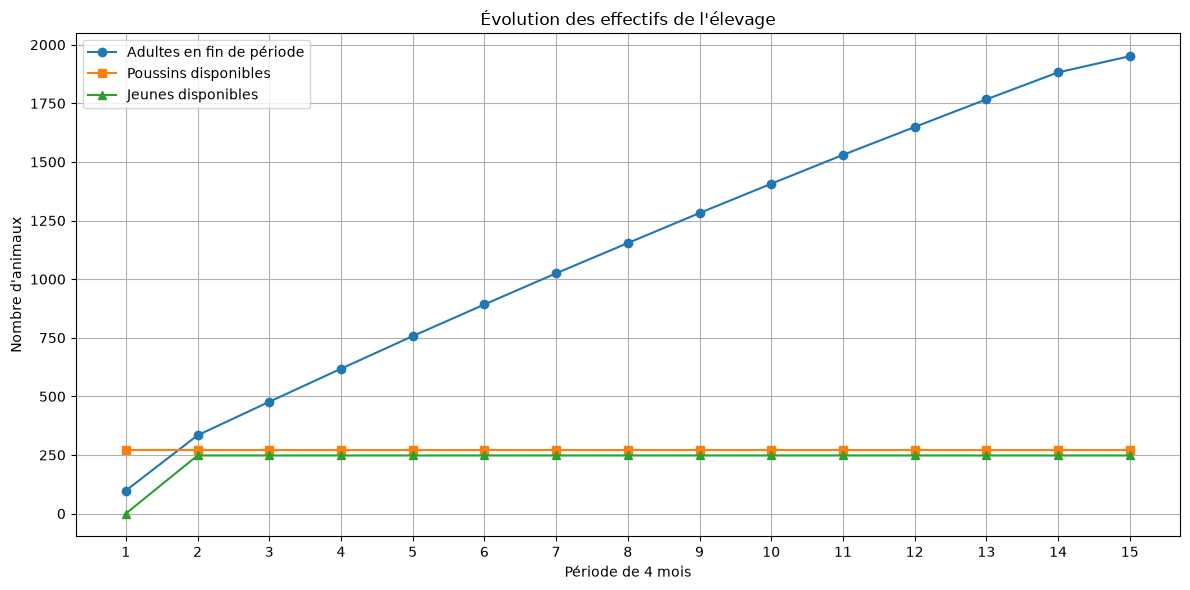

In [49]:
# 13.1 EVOLUTION DES POPULATIONS

if modele.sol_status in (1, 2):

    periodes = list(T)

    plt.figure(figsize=(12, 6))
    plt.plot(periodes, [A[t].varValue for t in T],
             marker="o", label="Adultes en fin de période")
    plt.plot(periodes, [P[t].varValue for t in T],
             marker="s", label="Poussins disponibles")
    plt.plot(periodes, [J[t].varValue for t in T],
             marker="^", label="Jeunes disponibles")

    plt.title("Évolution des effectifs de l'élevage")
    plt.xlabel("Période de 4 mois")
    plt.ylabel("Nombre d'animaux")
    plt.xticks(periodes)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


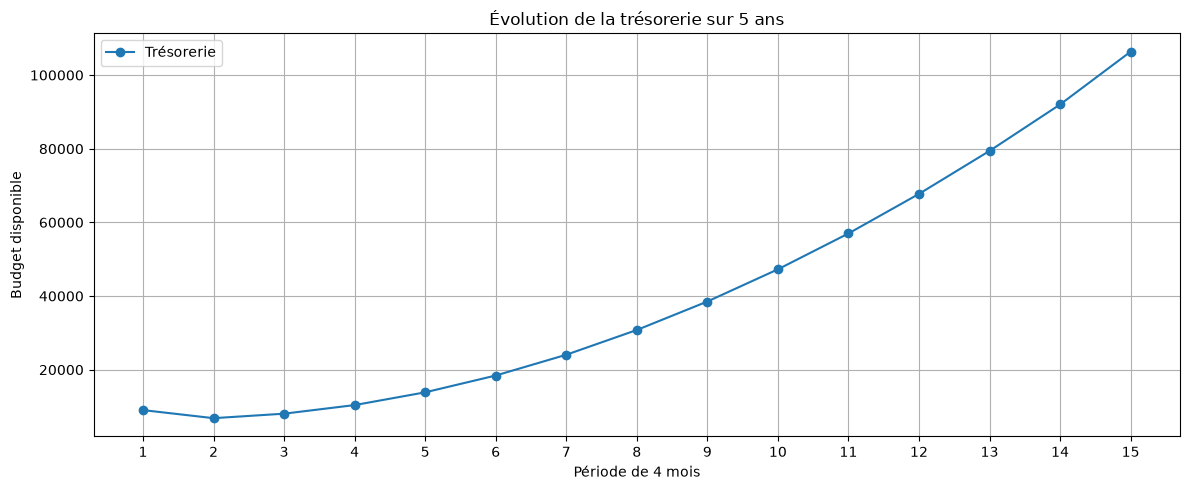

In [50]:
# 13.2 EVOLUTION DE LA TRESORERIE

if modele.sol_status in (1, 2):

    plt.figure(figsize=(12, 5))
    plt.plot(
        list(T),
        [B[t].varValue for t in T],
        marker="o",
        label="Trésorerie"
    )

    plt.title("Évolution de la trésorerie sur 5 ans")
    plt.xlabel("Période de 4 mois")
    plt.ylabel("Budget disponible")
    plt.xticks(list(T))
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


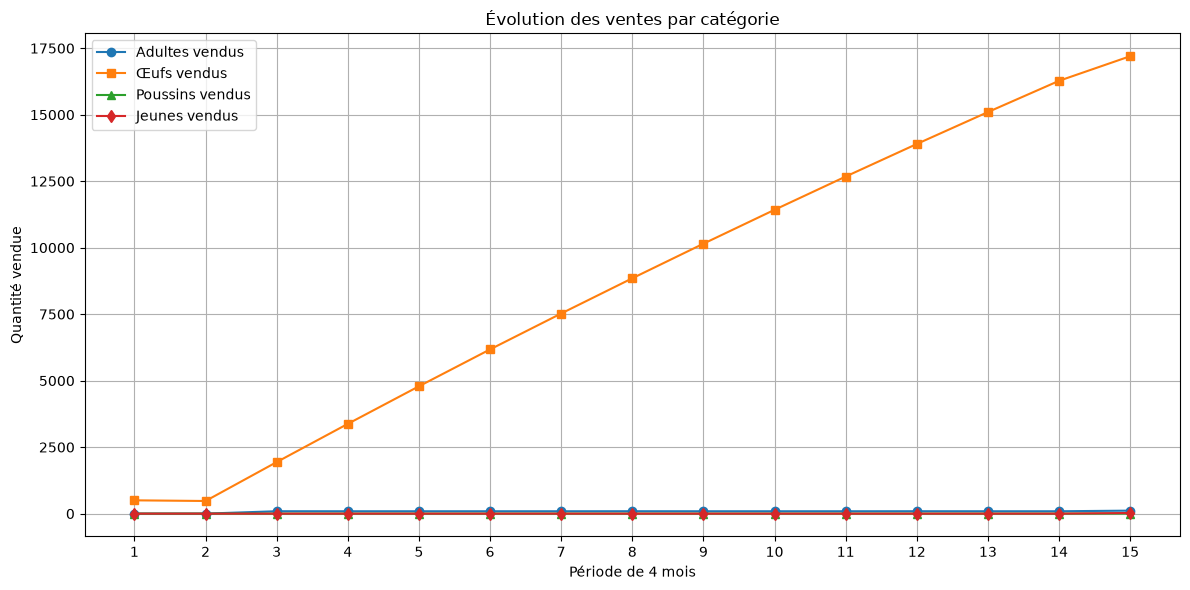

In [51]:
# 13.3 COMPARAISON DES VENTES

if modele.sol_status in (1, 2):

    periodes = list(T)

    plt.figure(figsize=(12, 6))
    plt.plot(periodes, [V_adultes[t].varValue for t in T],
             marker="o", label="Adultes vendus")
    plt.plot(periodes, [V_oeufs[t].varValue for t in T],
             marker="s", label="Œufs vendus")
    plt.plot(periodes, [V_poussins[t].varValue for t in T],
             marker="^", label="Poussins vendus")
    plt.plot(periodes, [V_jeunes[t].varValue for t in T],
             marker="d", label="Jeunes vendus")

    plt.title("Évolution des ventes par catégorie")
    plt.xlabel("Période de 4 mois")
    plt.ylabel("Quantité vendue")
    plt.xticks(periodes)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


## 14. Interprétation et limites
Les sexes sont distingués à tous les stades. La production dépend uniquement des femelles et un effectif de mâles est conservé. Examiner les ventes par sexe et le renouvellement des femelles.

Les données restent fictives. Les mortalités sont moyennes et les arrondis n'introduisent pas de véritable aléa. Le ratio de reproduction, le sexage précoce et la maturité après deux périodes sont des conventions à valider. Les adultes ne vieillissent pas dans le modèle. Prix, coûts et besoins en surface sont égaux entre sexes. Les flux financiers sont agrégés par période et le cheptel final a une valeur comptable. La réserve n'assure pas une liquidité quotidienne.

Les calculs interrompus fournissent des solutions réalisables, sans prouver l'optimum : il ne faut pas interpréter de petits écarts comme des effets économiques certains.

Les frais de transport sont calculés sur le poids des œufs et des trois catégories de pintades vendues. Il s’agit d’un coût proportionnel au poids, **pas d’une limite physique du nombre de trajets**. Les résultats présentés ci-dessous ont été recalculés avec ce coût de transport.


---
# 15. Extension expérimentale : demande du marché et réserve de sécurité

## Objectif scientifique

Le modèle sexué sans plafonds de marché autorise des ventes illimitées et une trésorerie minimale nulle. Nous introduisons deux hypothèses et comparons leurs effets **sans modifier les équations de base** :

- **H1 – Demande limitée :** chaque catégorie possède une demande maximale ($D^k_t$) par période. On impose $V^k_t\leq D^k_t$.
- **H2 – Réserve financière :** la trésorerie en fin de période doit rester supérieure ou égale à un seuil $B_t\geq B_{\min}$.

La comparaison porte sur les quatre configurations : M1 (référence), M2 (demande), M3 (réserve) et M4 (deux contraintes). Une contrainte additionnelle ne peut pas améliorer le maximum de la **même fonction objectif**, à paramètres inchangés. Si cela semble se produire, vérifier les statuts de résolution et la précision numérique.

In [59]:
# 15.1 Paramètres expérimentaux — À CALIBRER
# Nombre maximal d'unités vendues PAR PERIODE de quatre mois.
DEMANDE_PAR_PERIODE = {
    "adulte": 60,
    "oeuf": 700,
    "poussin": 120,
    "jeune": 100,
}
RESERVE_MINIMALE = 2000  # unités monétaires (€) en fin de période (valeur illustrative)

assert all(isinstance(v, int) and v >= 0 for v in DEMANDE_PAR_PERIODE.values())
assert 0 <= RESERVE_MINIMALE <= budget_initial
print("Hypothèses proposées :", DEMANDE_PAR_PERIODE, "réserve :", RESERVE_MINIMALE, "€ ")

Hypothèses proposées : {'adulte': 60, 'oeuf': 700, 'poussin': 120, 'jeune': 100} réserve : 2000 € 


## Construction des scénarios

On crée une **copie indépendante du modèle d'origine** : la fonction objectif, la mortalité, la croissance et les coûts restent strictement identiques. Seules les contraintes sélectionnées sont ajoutées. Cela permet une comparaison contrôlée, à condition que le solveur atteigne réellement le statut « Optimal » dans chaque scénario.

In [53]:
# 15.2 Fabrique de scénarios (n'altère jamais `modele`)
import copy

def fabriquer_scenario(demande=None, reserve=0):
    m = copy.deepcopy(modele)
    v = m.variablesDict()  # variables DE LA COPIE, pas du modèle d'origine
    if demande is not None:
        prefixes = {
            "adulte": "Adultes_vendus",
            "oeuf": "Oeufs_vendus",
            "poussin": "Poussins_vendus",
            "jeune": "Jeunes_vendus",
        }
        for t in T:
            for categorie, prefixe in prefixes.items():
                nom_var = f"{prefixe}_{t}"
                assert nom_var in v, f"Variable absente : {nom_var}"
                m += v[nom_var] <= demande[categorie], f"Demande_{categorie}_{t}"
    if reserve > 0:
        for t in T:
            nom_var = f"Budget_disponible_{t}"
            assert nom_var in v, f"Variable absente : {nom_var}"
            m += v[nom_var] >= reserve, f"Reserve_minimale_{t}"
    return m

# Contrôle que le modèle d'origine n'a pas été modifié
nb_contraintes_initiales = len(modele.constraints)
scenario_test = fabriquer_scenario(DEMANDE_PAR_PERIODE, RESERVE_MINIMALE)
assert len(modele.constraints) == nb_contraintes_initiales
assert len(scenario_test.constraints) == nb_contraintes_initiales + 4 * N_PERIODES + N_PERIODES
print("Modèle initial :", nb_contraintes_initiales, "contraintes")
print("Modèle enrichi :", len(scenario_test.constraints), "contraintes")

Modèle initial : 805 contraintes
Modèle enrichi : 880 contraintes


In [60]:
# 15.3 Résolution et comparaison
def resoudre_scenario(nom, demande=None, reserve=0):
    m = fabriquer_scenario(demande, reserve)
    solveur_scenario = pulp.PULP_CBC_CMD(msg=False, timeLimit=10, threads=1)
    m.solve(solveur_scenario)
    statut = "Optimal" if m.sol_status == 1 else "Réalisable" if m.sol_status == 2 else pulp.LpStatus[m.status]
    if m.sol_status not in (1,2):
        return {"Modèle": nom, "Statut": statut, "Richesse finale (UM)": None,
                "Trésorerie finale (UM)": None, "Adultes finaux": None}
    controler(m)
    variables = m.variablesDict()
    return {
        "Modèle": nom,
        "Statut": statut,
        "Richesse finale (UM)": round(pulp.value(m.objective), 2),
        "Trésorerie finale (UM)": round(variables[f"Budget_disponible_{N_PERIODES}"].varValue, 2),
        "Adultes finaux": round(variables[f"Stock_adultes_{N_PERIODES}"].varValue),
    }

comparaison = pd.DataFrame([
    resoudre_scenario("M1 – sexué sans demande"),
    resoudre_scenario("M2 – demande", demande=DEMANDE_PAR_PERIODE),
    resoudre_scenario("M3 – réserve", reserve=RESERVE_MINIMALE),
    resoudre_scenario("M4 – demande + réserve", demande=DEMANDE_PAR_PERIODE, reserve=RESERVE_MINIMALE),
])
display(comparaison)

if (comparaison["Statut"] == "Optimal").all():
    reference = comparaison.iloc[0]["Richesse finale (€)"]
    comparaison["Écart avec M1 (€)"] = comparaison["Richesse finale (€)"] - reference
    display(comparaison)
    assert all(comparaison["Richesse finale (€)"] <= reference + 0.02)
else:
    print("Attention : comparaison des objectifs suspendue (solution non optimale pour au moins un scénario).")

Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.


,Modèle,Statut,Richesse finale (UM),Trésorerie finale (UM),Adultes finaux
0,M1 – sexué sans demande,Optimal,158078.21,106363.21,1951
1,M2 – demande,Réalisable,47854.09,33503.09,455
2,M3 – réserve,Optimal,158078.21,106363.21,1951
3,M4 – demande + réserve,Réalisable,47765.80,33839.80,438


Attention : comparaison des objectifs suspendue (solution non optimale pour au moins un scénario).


## Analyse de sensibilité

On fait varier le plafond de demande en conservant les **mêmes proportions entre catégories**. L'objectif est d'identifier à partir de quel niveau de demande cette contrainte ne limite plus la richesse finale. Les coefficients choisis sont des expériences numériques, pas des prévisions commerciales.

Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.


,Modèle,Statut,Richesse finale (UM),Trésorerie finale (UM),Adultes finaux,Multiplicateur de demande
0,x0.5,Réalisable,33627.67,19401.67,450,0.50
1,x0.75,Réalisable,41501.54,27175.54,454,0.75
2,x1,Réalisable,47854.09,33503.09,455,1.00
3,x1.5,Réalisable,58325.58,43299.58,482,1.50
4,x2,Réalisable,64824.89,49148.89,508,2.00
5,x3,Réalisable,77450.00,61624.00,514,3.00


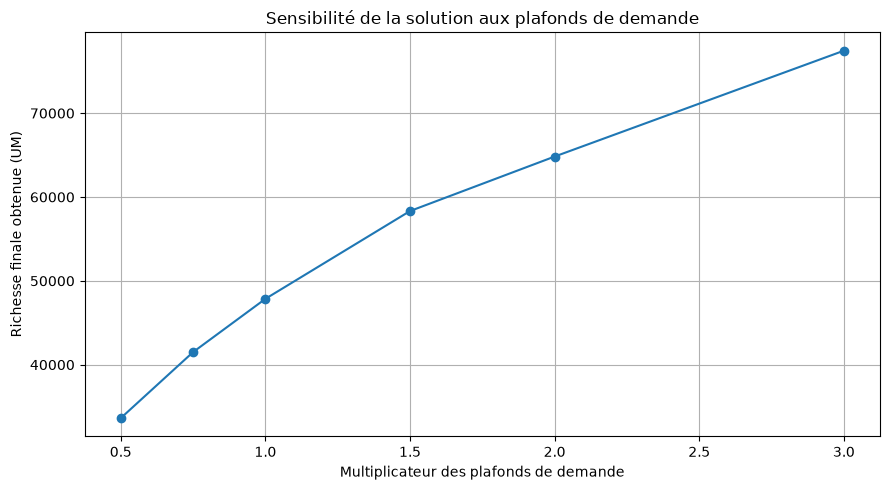

In [62]:
# 15.4 Sensibilité à la demande
multiplicateurs = [0.5, 0.75, 1, 1.5, 2, 3]
lignes = []
for facteur in multiplicateurs:
    demande_variante = {k: int(v * facteur) for k, v in DEMANDE_PAR_PERIODE.items()}
    ligne = resoudre_scenario(f"x{facteur}", demande=demande_variante)
    ligne["Multiplicateur de demande"] = facteur
    lignes.append(ligne)
sensibilite_demande = pd.DataFrame(lignes)
display(sensibilite_demande)

optimaux = sensibilite_demande[sensibilite_demande["Statut"].isin(["Optimal", "Réalisable"])]
if not optimaux.empty:
    plt.figure(figsize=(9, 5))
    plt.plot(optimaux["Multiplicateur de demande"], optimaux["Richesse finale (UM)"], marker="o")
    plt.xlabel("Multiplicateur des plafonds de demande")
    plt.ylabel("Richesse finale obtenue (UM)")
    plt.title("Sensibilité de la solution aux plafonds de demande")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## 16. Résultats par sexe et contrôle de la solution
Cette vérification est appliquée à la solution du modèle sexué de base. Les scénarios de la section 15 ont les mêmes bilans biologiques ; leur réalisabilité est aussi contrôlée après résolution.

Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.


,Période,Adultes F,Reproducteurs F,Adultes vendus F,Poussins F,Jeunes F,Adultes M,Reproducteurs M,Adultes vendus M,Poussins M,Jeunes M
0,1,78,80,0,135,0,20,20,0,135,0
1,2,195,78,0,135,124,139,20,0,135,124
2,3,310,195,0,135,124,167,49,90,135,124
3,4,423,310,0,135,124,195,78,89,135,124
4,5,534,423,0,135,124,223,106,89,135,124
5,6,642,534,0,135,124,250,134,89,135,124
6,7,748,642,0,135,124,277,161,89,135,124
7,8,852,748,0,135,124,302,187,90,135,124
8,9,954,852,0,135,124,328,213,89,135,124
9,10,1054,954,0,135,124,353,239,89,135,124


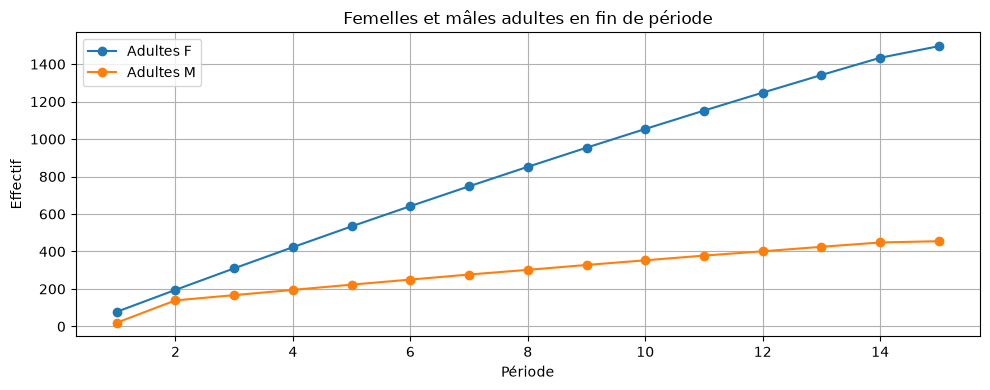

Contrôles du modèle sexué réussis.
Capacité contrôlée pendant ET à la clôture des 15 périodes.
Richesse reconstituée : 158078.21 €


In [63]:
# Contrôle commun défini au début du notebook.
controler(modele)
sexes = []
for t in T:
    ligne = {"Période": t}
    for s in SEXES:
        ligne[f"Adultes {s}"] = round(pulp.value(A_sexe[s][t]))
        ligne[f"Reproducteurs {s}"] = round(pulp.value(R_A_sexe[s][t]))
        ligne[f"Adultes vendus {s}"] = round(pulp.value(V_A_sexe[s][t]))
        ligne[f"Poussins {s}"] = round(pulp.value(P_sexe[s][t]))
        ligne[f"Jeunes {s}"] = round(pulp.value(J_sexe[s][t]))
    assert ligne["Reproducteurs F"] <= femelles_par_male * ligne["Reproducteurs M"]
    assert ligne["Poussins F"] + ligne["Poussins M"] == round(pulp.value(P[t]))
    sexes.append(ligne)
df_sexes = pd.DataFrame(sexes)
display(df_sexes)
df_sexes.plot(x="Période", y=["Adultes F", "Adultes M"], marker="o", figsize=(10,4))
plt.title("Femelles et mâles adultes en fin de période")
plt.ylabel("Effectif"); plt.grid(); plt.tight_layout(); plt.show()
print("Contrôles du modèle sexué réussis.")

# Vérification indépendante de la capacité en clôture et de la richesse finale.
for t in T:
    occupation_pendant = (surface["adulte"] * R_adultes[t].varValue
                         + surface["poussin"] * C_poussins[t].varValue
                         + surface["jeune"] * C_jeunes[t].varValue)
    occupation_cloture = (surface["adulte"] * A[t].varValue
                         + surface["poussin"] * (C_poussins[t].varValue - M_poussins[t].varValue))
    assert occupation_pendant <= surface["surface_max"] + 1e-4, f"Surface pendant t={t}"
    assert occupation_cloture <= surface["surface_max"] + 1e-4, f"Surface clôture t={t}"

richesse_reconstituee = (B[N_PERIODES].varValue
                        + valeur_residuelle["adulte"] * A[N_PERIODES].varValue
                        + valeur_residuelle["jeune"] * (
                            C_poussins[N_PERIODES].varValue - M_poussins[N_PERIODES].varValue))
assert abs(richesse_reconstituee - pulp.value(modele.objective)) < 1e-3
print("Capacité contrôlée pendant ET à la clôture des 15 périodes.")
print("Richesse reconstituée :", round(richesse_reconstituee, 2), "€")


## 17. Sensibilité simple : combien de femelles par mâle ?
On teste **2, 4 et 6 femelles par mâle**, sans modifier les autres paramètres. Ces valeurs sont des expériences, pas des recommandations biologiques. Un ratio plus faible impose davantage de mâles ; un ratio plus élevé permet de conserver proportionnellement plus de femelles. Les résultats peuvent être irréguliers si la résolution est interrompue avant preuve d'optimalité.

Dans chaque copie, seule la contrainte $R^A_{F,t}\le rR^A_{M,t}$ est remplacée. Le modèle de base est conservé.

Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.
Contrôles réussis : effectifs et contraintes vérifiés ; tolérance monétaire de 0,01 €.


,Femelles par mâle,Richesse,Statut,Optimalité prouvée
0,2,130390.444,Optimal prouvé,True
1,4,158078.210,Optimal prouvé,True
2,6,165278.780,Optimal prouvé,True


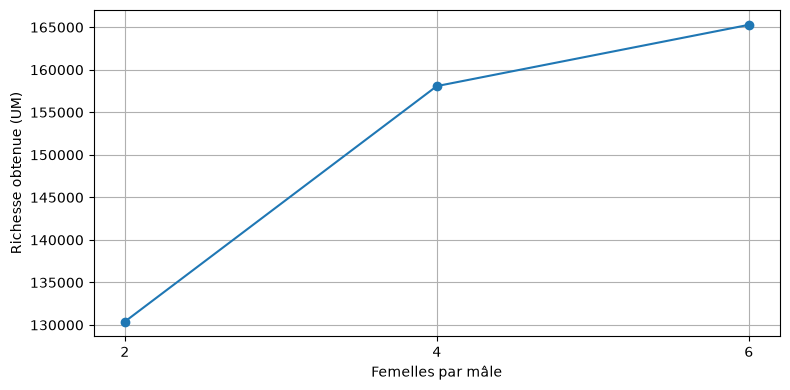

In [58]:
# Étude de sensibilité : remplacement du ratio de reproduction sur des copies.
lignes_ratio = []
for ratio in [2, 4, 6]:
    m = copy.deepcopy(modele)
    variables = m.variablesDict()
    for t in T:
        del m.constraints[f"Reproduction_{t}"]
        m += (variables[f"R_A_sexe_F_{t}"] <=
              ratio * variables[f"R_A_sexe_M_{t}"]), f"Reproduction_{t}"
    m.solve(pulp.PULP_CBC_CMD(msg=False, timeLimit=60, threads=1))
    if m.sol_status in (1, 2):
        controler(m)
        richesse = pulp.value(m.objective)
    else:
        richesse = None
    lignes_ratio.append({
        "Femelles par mâle": ratio,
        "Richesse": richesse,
        "Statut": "Optimal prouvé" if m.sol_status == 1 else (
            "Réalisable, non prouvé optimal" if m.sol_status == 2 else pulp.LpStatus[m.status]),
        "Optimalité prouvée": m.sol_status == 1,
    })
sensibilite_ratio = pd.DataFrame(lignes_ratio)
display(sensibilite_ratio)
if sensibilite_ratio["Richesse"].notna().any():
    sensibilite_ratio.plot(x="Femelles par mâle", y="Richesse", marker="o", legend=False, figsize=(8,4))
    plt.xticks([2, 4, 6]); plt.ylabel("Richesse obtenue (UM)")
    plt.grid(); plt.tight_layout(); plt.show()
if not sensibilite_ratio["Optimalité prouvée"].all():
    print("Attention : aucune conclusion définitive sur les écarts sans preuve d'optimalité.")

## 18. Conclusion des résultats recalculés

Avec les paramètres retenus, le modèle principal fournit une **solution optimale prouvée**
sur cinq ans. La richesse finale atteint **158 078,21 €**, dont **106 363,21 € de trésorerie**
et **51 715,00 € de valeur du cheptel restant**.

La stratégie développe les reproducteurs et privilégie les ventes d'œufs : sur les
15 périodes, elle vend **130 351 œufs, 1 183 adultes, 4 poussins et 24 jeunes**.
Elle conserve une partie des animaux pour renouveler et augmenter la production ;
le cheptel adulte final atteint **1 951 animaux**, contre 100 au départ.
Les œufs représentent la principale source de recettes brutes dans ce scénario.
Ces choix résultent des prix, des coûts et des contraintes supposés dans le modèle.

Le coût total du transport est de **607,89 €**, calculé avant arrondi avec le tarif
proportionnel de **0,04 €/kg vendu**. La somme des coûts déjà arrondis ligne par ligne
peut différer de quelques centimes ; le bilan utilise les valeurs non arrondies.

Le scénario principal suppose que toutes les quantités proposées à la vente trouvent
acheteur. Avec les plafonds de demande, une solution réalisable atteint **47 854,09 €**
de richesse finale ; avec demande et réserve, elle atteint **47 765,80 €**.
Ces deux solutions ne sont pas prouvées optimales : leurs écarts ne mesurent donc pas
exactement le coût des contraintes. La réserve seule n'altère pas l'optimum obtenu.

La richesse finale n'est pas un bénéfice net : elle comprend les ressources de départ
et la valeur des animaux restants. Les données sont fictives et certains coûts réels
ne sont pas représentés. Le projet illustre donc une méthode d'aide à la décision,
sans constituer une prévision validée de la rentabilité d'un élevage réel.
